# Étape 3 — Fouille des données

**Objectif :** extraire de l'information des analyses de gaz dissous des transformateurs, avec deux approches :
- **classification supervisée** : apprendre à prédire si l'expert a recommandé une action, à partir des gaz ;
- **clustering (non supervisé)** : regrouper les prélèvements qui ont des profils de gaz semblables.

**Données :** la table prétraitée à l'étape 2 (`dga_transformateurs_pretraite.csv`) + l'avis de l'expert (tables brutes `AnalyseDetail` et `Recommandation`).

**Plan :**
1. Importer les bibliothèques
2. Charger les données
3. Construire la cible : « action recommandée »
4. Classification : KNN, arbre de décision, forêt aléatoire
5. Clustering : K-Means, CAH, DBSCAN
6. Bilan

## 1. Importer les bibliothèques

In [10]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Modèles de classification
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Méthodes de clustering
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from scipy.cluster.hierarchy import dendrogram, linkage

# Préparation et mesures de performance
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, recall_score, precision_score,
                             f1_score, roc_auc_score, roc_curve, silhouette_score)

sns.set_theme(style="whitegrid")
COULEURS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
print("Bibliothèques importées.")

Bibliothèques importées.


## 2. Charger les données

In [11]:
dossier = Path.cwd() / "data"

# Table de l'étape 2 : un prélèvement de gaz dissous par ligne, déjà nettoyé
table = pd.read_csv(dossier / "processed" / "dga_transformateurs_pretraite.csv",
                    dtype={"NoÉquipement": str}, parse_dates=["DatePrélèvement"])

# Tables brutes de l'étape 1 contenant l'avis de l'expert
detail = pd.read_csv(dossier / "raw" / "AnalyseDetail.csv")            # code de recommandation de chaque prélèvement
recommandations = pd.read_csv(dossier / "raw" / "Recommandation.csv")  # texte de chaque code

print("Table prétraitée :", table.shape)
print("Transformateurs  :", table["NoÉquipement"].nunique())

Table prétraitée : (4338, 35)
Transformateurs  : 292


## 3. Construire la cible : « action recommandée »
La base ne contient pas de colonne « panne ». En revanche, pour chaque prélèvement, l'expert a choisi une **recommandation** :
- son **code** est dans la table `AnalyseDétail` (colonne `CodeRecommandation`) ;
- son **texte** est dans la table `Recommandation`. Un même code n'a pas le même sens selon l'essai : on prend donc les textes de l'essai **GD** (gaz dissous).

**Règle :** `action` = **0** si le texte est « Aucune action », **1** pour toute autre recommandation, et **inconnu** s'il n'y a pas de texte.

In [12]:
# 1. Le code de recommandation de chaque prélèvement (jointure sur la clé du prélèvement)
table = table.merge(detail[["CléAnalyse", "CodeRecommandation"]], on="CléAnalyse", how="left")

# 2. Le texte correspondant, parmi les recommandations de l'essai GD
reco_gd = recommandations[recommandations["TypeAnalyse"] == "GD"][["CodeRecommandation", "Recommandation"]]
table = table.merge(reco_gd, on="CodeRecommandation", how="left")

# Quelles recommandations l'expert a-t-il données ?
table["Recommandation"].value_counts(dropna=False)

Recommandation
Aucune action                                                                                                                3610
NaN                                                                                                                           468
Reprise d'une seringue pour l'analyse GD pour la date ci-dessous                                                              195
Autre recommandation (spécifier)                                                                                               21
Reprise d'une seringue pour l'analyse GD et de l'eau dissoute dans l'huile d'ici la date ci-dessous                            14
Laisser en service et reprendre une seringue pour analyse GD pour la date ci--dessous et planifier une inspection interne      11
Mettre hors service IMMÉDIATEMENT et planifier une inspection interne                                                           8
Reprise d'une seringue pour l'analyse GD dans les 24 heures et expédier d'u

In [13]:
# 3. La cible : 0 = aucune action, 1 = action, NaN = inconnu (pas de texte)
table["action"] = np.where(table["Recommandation"] == "Aucune action", 0, 1)
table.loc[table["Recommandation"].isna(), "action"] = np.nan

print(table["action"].value_counts(dropna=False))
print("\nPart des prélèvements avec action (cible connue) :", round(table["action"].mean(), 3))

action
0.000    3610
NaN       468
1.000     260
Name: count, dtype: int64

Part des prélèvements avec action (cible connue) : 0.067


**Interprétation :** 
- **3 610** prélèvements « Aucune action » (0), **260** avec une action (1), soit **6,7 %** des cibles connues.
- **468** prélèvements n'ont pas de texte de recommandation (code 0 ou absent) : leur cible est inconnue, ils sont **exclus** de la classification (on n'invente pas de réponse).
- Les actions sont surtout des demandes de **surveillance** : 195 des 260 (75 %) sont « Reprise d'une seringue pour l'analyse GD ». Les interventions lourdes sont rares (8 « Mettre hors service IMMÉDIATEMENT »).

→ La cible signifie donc : **« l'expert a jugé que ce prélèvement demandait une suite »** (surveillance renforcée ou intervention), et non « le transformateur est en panne ».

## 4. Classification supervisée
**Question :** à partir des 7 gaz de défaut, peut-on prédire si l'expert va recommander une action ?

Les variables d'entrée sont les **gaz après logarithme** (colonnes `log_…` de l'étape 2). On n'utilise pas les colonnes `std_…`, car leur moyenne
et leur écart-type ont été calculés sur toutes les données, y compris celles du test (voir 4.2).

### 4.1 Découpage entraînement / test chronologique
On entraîne les modèles sur les **80 % de prélèvements les plus anciens** et on les teste sur les **20 % les plus récents** :
c'est la situation réelle (on apprend du passé pour prédire l'avenir).

In [14]:
gaz = ["H2", "CH4", "C2H2", "C2H4", "C2H6", "CO", "CO2"]
variables = ["log_" + g for g in gaz]

# On garde seulement les prélèvements dont la cible est connue
donnees = table.dropna(subset=["action"])

# Date qui sépare les 80 % de prélèvements les plus anciens des 20 % les plus récents
date_coupure = donnees["DatePrélèvement"].quantile(0.8)
train = donnees[donnees["DatePrélèvement"] < date_coupure]
test = donnees[donnees["DatePrélèvement"] >= date_coupure]

X_train, y_train = train[variables], train["action"].astype(int)   # X = entrées, y = cible
X_test, y_test = test[variables], test["action"].astype(int)

print("Date de coupure :", date_coupure.date())
print(f"Entraînement : {len(train)} prélèvements ({train['DatePrélèvement'].min():%Y} à {train['DatePrélèvement'].max():%Y}), {y_train.mean():.1%} d'actions")
print(f"Test         : {len(test)} prélèvements ({test['DatePrélèvement'].min():%Y} à {test['DatePrélèvement'].max():%Y}), {y_test.mean():.1%} d'actions")

Date de coupure : 2005-01-28
Entraînement : 3095 prélèvements (1984 à 2005), 7.3% d'actions
Test         : 775 prélèvements (2005 à 2009), 4.5% d'actions


### 4.2 Standardisation (pour le KNN)
Le KNN mesure des distances : il faut des variables à la même échelle. La moyenne et l'écart-type sont calculés **sur l'entraînement uniquement**,
puis appliqués au test : sinon le modèle « verrait » des informations du test pendant l'apprentissage (fuite d'information).
Les arbres n'en ont pas besoin, mais cela ne les gêne pas.

In [15]:
standardiseur = StandardScaler()
X_train_std = standardiseur.fit_transform(X_train)   # fit : calcule moyenne et écart-type sur l'entraînement
X_test_std = standardiseur.transform(X_test)         # transform : applique ces mêmes valeurs au test

### 4.3 Entraîner et comparer les 3 modèles

| Modèle | Principe | Réglages |
|---|---|---|
| **KNN** | regarde les 15 prélèvements les plus proches et vote | `n_neighbors=15` |
| **Arbre de décision** | suite de questions oui/non sur les gaz | au plus 5 questions (`max_depth=5`) |
| **Forêt aléatoire** | 300 arbres qui votent | `n_estimators=300` |

Les actions ne représentent qu'environ 7 % des cas : un modèle paresseux qui répondrait toujours « aucune action » aurait 93 % de bonnes réponses !
`class_weight="balanced"` donne plus de poids aux cas rares (« action ») pour l'arbre et la forêt (le KNN n'a pas ce réglage).

**Lire les mesures :**
- **Rappel** : parmi les vraies actions, la part retrouvée par le modèle (actions manquées = rappel faible).
- **Précision** : parmi les alertes du modèle, la part qui correspond à une vraie action (beaucoup de fausses alertes = précision faible).
- **F1** : moyenne du rappel et de la précision ; élevé seulement si les deux sont bons.
- **AUC** : capacité à classer les prélèvements « action » au-dessus des autres (0,5 = hasard, 1 = parfait).

In [16]:
modeles = {
    "KNN": KNeighborsClassifier(n_neighbors=15),
    "Arbre de décision": DecisionTreeClassifier(max_depth=5, min_samples_leaf=10, class_weight="balanced", random_state=42),
    "Forêt aléatoire": RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight="balanced",
                                              random_state=42, n_jobs=-1),
}

resultats = []
for nom, modele in modeles.items():
    modele.fit(X_train_std, y_train)                      # apprentissage
    prediction = modele.predict(X_test_std)               # 0 ou 1 pour chaque prélèvement du test
    probabilite = modele.predict_proba(X_test_std)[:, 1]  # probabilité d'être "action"
    resultats.append({"Modèle": nom,
                      "Rappel": recall_score(y_test, prediction),
                      "Précision": precision_score(y_test, prediction, zero_division=0),
                      "F1": f1_score(y_test, prediction),
                      "AUC": roc_auc_score(y_test, probabilite)})

comparaison = pd.DataFrame(resultats).set_index("Modèle")
comparaison

,Rappel,Précision,F1,AUC
Modèle,,,,
KNN,0.114,0.364,0.174,0.800
Arbre de décision,0.371,0.112,0.172,0.537
Forêt aléatoire,0.514,0.220,0.308,0.819


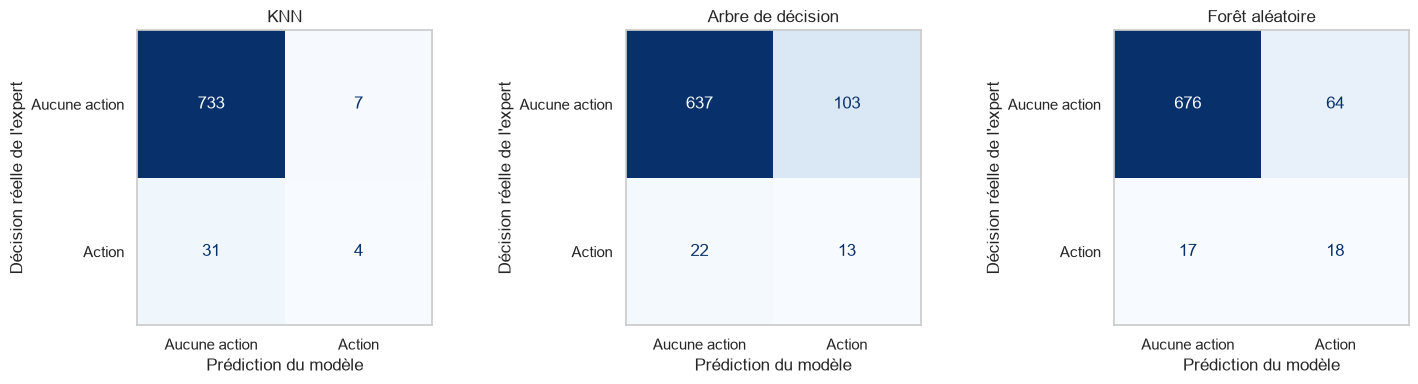

In [17]:
# Matrices de confusion : lignes = réalité, colonnes = prédiction du modèle
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (nom, modele) in zip(axes, modeles.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, modele.predict(X_test_std), ax=ax, colorbar=False,
                                            display_labels=["Aucune action", "Action"], cmap="Blues")
    ax.set_title(nom)
    ax.set_xlabel("Prédiction du modèle")
    ax.set_ylabel("Décision réelle de l'expert")
    ax.grid(False)
plt.tight_layout()
plt.show()

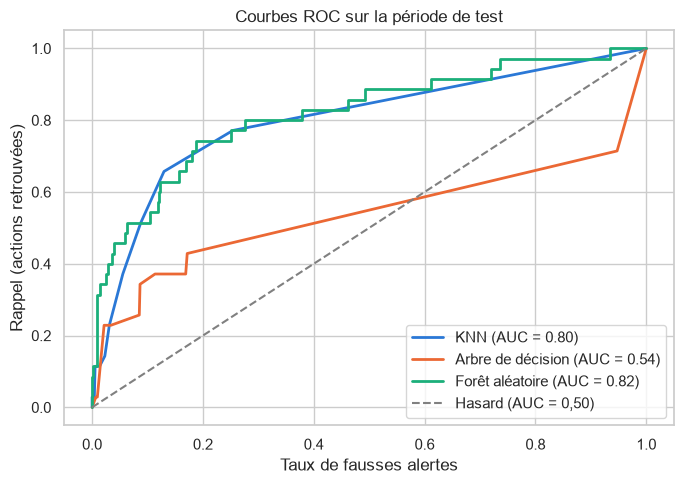

In [18]:
# Courbes ROC : rappel en fonction du taux de fausses alertes, pour tous les seuils de décision
fig, ax = plt.subplots(figsize=(7, 5))
for i, (nom, modele) in enumerate(modeles.items()):
    probabilite = modele.predict_proba(X_test_std)[:, 1]
    taux_faux_positifs, rappel, _ = roc_curve(y_test, probabilite)
    ax.plot(taux_faux_positifs, rappel, color=COULEURS[i], linewidth=2,
            label=f"{nom} (AUC = {roc_auc_score(y_test, probabilite):.2f})")
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Hasard (AUC = 0,50)")
ax.set_xlabel("Taux de fausses alertes")
ax.set_ylabel("Rappel (actions retrouvées)")
ax.set_title("Courbes ROC sur la période de test")
ax.legend()
plt.tight_layout()
plt.show()

**Interprétation :** 
La période de test (2005-2009) compte 775 prélèvements, dont **35 actions** (4,5 %).
- **KNN** : il ne donne que 11 alertes et ne retrouve que **4 actions sur 35** (rappel 11 %). Comme les actions sont rares et que le KNN ne peut pas les « surpondérer », il répond presque toujours « aucune action ».
- **Arbre de décision** : il retrouve 13 actions sur 35 (37 %), mais au prix de **103 fausses alertes** (précision 11 %). Son AUC de 0,54 est proche du hasard : un seul arbre de 5 questions appris sur 1984-2005 se généralise mal à 2005-2009.
- **Forêt aléatoire** : **le meilleur modèle**. Elle retrouve **18 actions sur 35** (rappel 51 %) avec 64 fausses alertes (précision 22 %), et a la meilleure AUC (**0,82**).

**Conclusion :** les gaz expliquent une **bonne partie** de la décision de l'expert, mais pas tout. L'expert tient aussi compte d'informations absentes du modèle : l'historique du transformateur (les gaz augmentent-ils ?), les autres essais d'huile, son expérience. On remarque aussi que la part d'actions baisse entre l'entraînement (7,3 %) et le test (4,5 %) : les pratiques de recommandation ont évolué dans le temps.

### 4.4 Quels gaz expliquent la décision de l'expert ?
La forêt aléatoire indique l'**importance** de chaque variable : la part des décisions des arbres qui repose sur ce gaz (le total vaut 100 %).

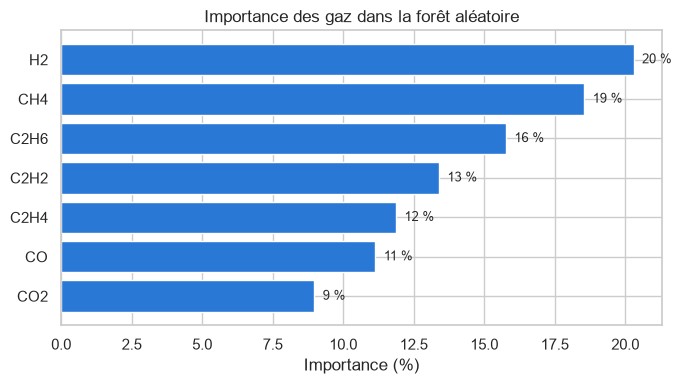

In [19]:
importance = pd.Series(modeles["Forêt aléatoire"].feature_importances_, index=gaz).sort_values()

fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(importance.index, importance.values * 100, color=COULEURS[0])
for y, v in enumerate(importance.values * 100):
    ax.text(v + 0.3, y, f"{v:.0f} %", va="center", fontsize=9)
ax.set_xlabel("Importance (%)")
ax.set_title("Importance des gaz dans la forêt aléatoire")
plt.tight_layout()
plt.show()

**Interprétation :** 
- Les gaz les plus utilisés sont **H2 (20 %)**, **CH4 (19 %)** et **C2H6 (16 %)**, puis l'acétylène **C2H2 (13 %)**.
- **CO et CO2** (vieillissement du papier) sont les **moins** utilisés (11 % et 9 %).

→ Les recommandations de l'expert réagissent surtout aux gaz signalant un **défaut actif** (décharges partielles, surchauffe de l'huile, arc), et beaucoup moins au vieillissement normal du papier. C'est cohérent avec la pratique : un défaut actif demande une surveillance rapprochée, le vieillissement est lent et attendu.

## 5. Clustering (non supervisé)
Ici, **aucune cible** : on cherche des groupes de prélèvements aux profils de gaz semblables.
On utilise les 7 gaz **standardisés** de l'étape 2 (colonnes `std_…`) et tous les prélèvements (4 338).
Les groupes obtenus seront ensuite comparés à la décision de l'expert.

### 5.1 K-Means : choisir le nombre de groupes
On teste de 2 à 7 groupes avec deux critères :
- **Inertie** : dispersion à l'intérieur des groupes. Elle baisse toujours quand k augmente ; on cherche le « coude ».
- **Silhouette** (entre −1 et 1) : proche de 1 = groupes bien séparés ; vers 0,3 = séparation faible ; proche de 0 = groupes qui se chevauchent.

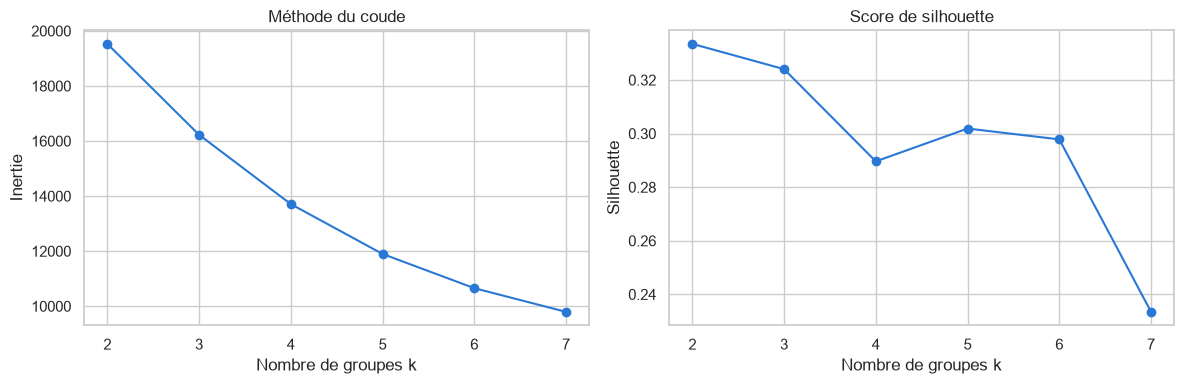

,k,inertie,silhouette
0,2,"19,529.044",0.333
1,3,"16,226.166",0.324
2,4,"13,709.309",0.290
3,5,"11,898.004",0.302
4,6,"10,654.522",0.298
5,7,"9,794.158",0.233


In [20]:
X = table[["std_" + g for g in gaz]]

scores = []
for k in range(2, 8):
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=42)   # n_init=10 : 10 essais, on garde le meilleur
    groupes = kmeans.fit_predict(X)
    scores.append({"k": k, "inertie": kmeans.inertia_,
                   "silhouette": silhouette_score(X, groupes, sample_size=2000, random_state=42)})
scores = pd.DataFrame(scores)

# Deux graphiques côte à côte : coude (inertie) et silhouette
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(scores["k"], scores["inertie"], marker="o", color=COULEURS[0])
axes[0].set(title="Méthode du coude", xlabel="Nombre de groupes k", ylabel="Inertie")
axes[1].plot(scores["k"], scores["silhouette"], marker="o", color=COULEURS[0])
axes[1].set(title="Score de silhouette", xlabel="Nombre de groupes k", ylabel="Silhouette")
plt.tight_layout()
plt.show()
scores

**Interprétation :** 
- La **silhouette est la plus élevée pour k = 2** (0,33), à peine devant k = 3 (0,32), puis elle baisse.
- La courbe d'inertie ne présente pas de coude net.
- Une silhouette d'environ 0,33 indique une **séparation faible** : les groupes existent, mais ils se chevauchent. Les prélèvements forment plutôt un **continuum** que des familles bien distinctes.

→ On retient **k = 2**.

In [21]:
k = 2
kmeans = KMeans(n_clusters=k, n_init=10, random_state=42)
table["groupe_kmeans"] = kmeans.fit_predict(X)

# Profil de chaque groupe : médiane des gaz en ppm + nombre de prélèvements + part d'actions recommandées
profil = table.groupby("groupe_kmeans")[gaz].median()
profil["nb_prélèvements"] = table["groupe_kmeans"].value_counts()
profil["% action expert"] = table.groupby("groupe_kmeans")["action"].mean() * 100
profil.round(1)

,H2,CH4,C2H2,C2H4,C2H6,CO,CO2,nb_prélèvements,% action expert
groupe_kmeans,,,,,,,,,
0,7.300,2.700,0.000,10.000,1.000,261.000,"1,596.000",2112,2.000
1,31.000,13.000,0.200,42.000,9.000,619.500,"4,305.000",2226,11.500


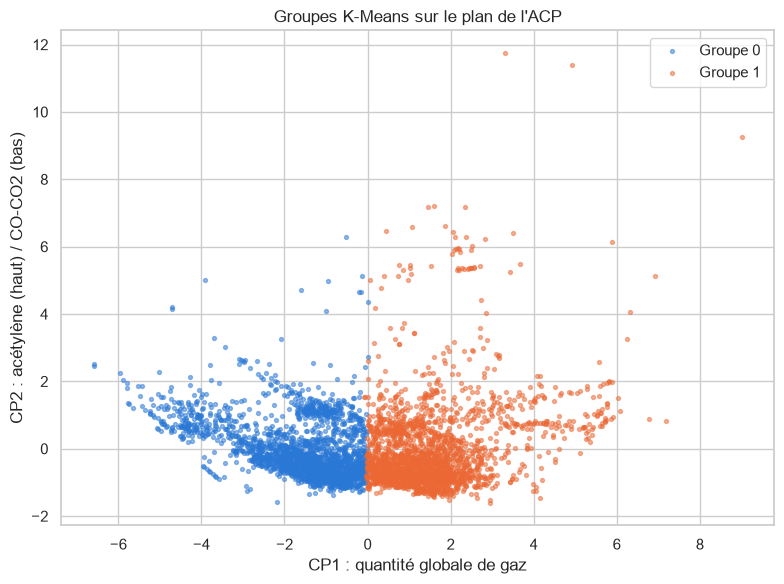

In [22]:
# Les groupes sur le plan de l'ACP de l'étape 2 (CP1 = quantité de gaz, CP2 = acétylène vs CO/CO2)
fig, ax = plt.subplots(figsize=(8, 6))
for g in range(k):
    points = table[table["groupe_kmeans"] == g]
    ax.scatter(points["CP1"], points["CP2"], s=8, alpha=0.5, color=COULEURS[g], label=f"Groupe {g}")
ax.set(xlabel="CP1 : quantité globale de gaz", ylabel="CP2 : acétylène (haut) / CO-CO2 (bas)",
       title="Groupes K-Means sur le plan de l'ACP")
ax.legend()
plt.tight_layout()
plt.show()

**Interprétation :** 
- La **silhouette est la plus élevée pour k = 2** (0,33), à peine devant k = 3 (0,32), puis elle baisse.
- La courbe d'inertie ne présente pas de coude net.
- Une silhouette d'environ 0,33 indique une **séparation faible** : les groupes existent, mais ils se chevauchent. Les prélèvements forment plutôt un **continuum** que des familles bien distinctes.

→ On retient **k = 2**.MEANS

### 5.2 CAH (classification ascendante hiérarchique)
La CAH part de chaque prélèvement seul, puis fusionne pas à pas les groupes les plus proches (méthode de **Ward**).
Le **dendrogramme** montre ces fusions : une grande « marche » verticale indique une bonne coupure.
Le calcul compare tous les prélèvements deux à deux : on travaille sur un **échantillon de 1 000 prélèvements** tirés au hasard.

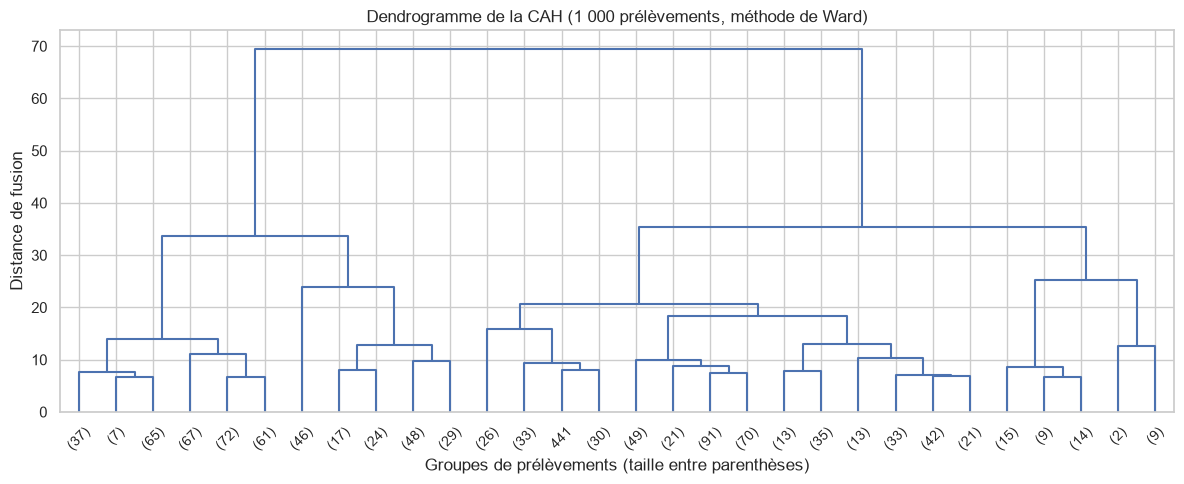

,k,silhouette
0,2,0.325
1,3,0.319
2,4,0.263
3,5,0.266
4,6,0.271
5,7,0.274


In [23]:
echantillon = X.sample(n=1000, random_state=42)        # 1 000 prélèvements tirés au hasard (toujours les mêmes)
liaisons = linkage(echantillon, method="ward")

fig, ax = plt.subplots(figsize=(12, 5))
dendrogram(liaisons, truncate_mode="lastp", p=30, ax=ax, color_threshold=0)   # on n'affiche que les 30 dernières fusions
ax.set(title="Dendrogramme de la CAH (1 000 prélèvements, méthode de Ward)",
       xlabel="Groupes de prélèvements (taille entre parenthèses)", ylabel="Distance de fusion")
plt.tight_layout()
plt.show()

# Silhouette de la CAH pour 2 à 7 groupes
scores_cah = []
for nb in range(2, 8):
    groupes = AgglomerativeClustering(n_clusters=nb, linkage="ward").fit_predict(echantillon)
    scores_cah.append({"k": nb, "silhouette": silhouette_score(echantillon, groupes)})
pd.DataFrame(scores_cah)

**Interprétation :** 
- Sur le dendrogramme, la **plus grande marche** est la dernière fusion (distance d'environ 70, contre 35 pour la précédente) : couper l'arbre en **2 groupes** est le choix le plus naturel.
- La silhouette de la CAH est aussi maximale pour **k = 2** (0,33).

→ La CAH, une méthode différente, **confirme K-Means** : les prélèvements se partagent en deux grandes familles, peu gazés et plus gazés.

### 5.3 DBSCAN : zones denses et points isolés
DBSCAN forme des groupes là où les points sont **serrés**, et classe les points isolés comme **bruit** (étiquette −1).
Deux réglages : `min_samples` (nombre minimal de voisins) et `eps` (rayon du voisinage).
Pour choisir `eps`, on trace la distance de chaque prélèvement à son 10e voisin : le « coude » de la courbe est une bonne valeur.

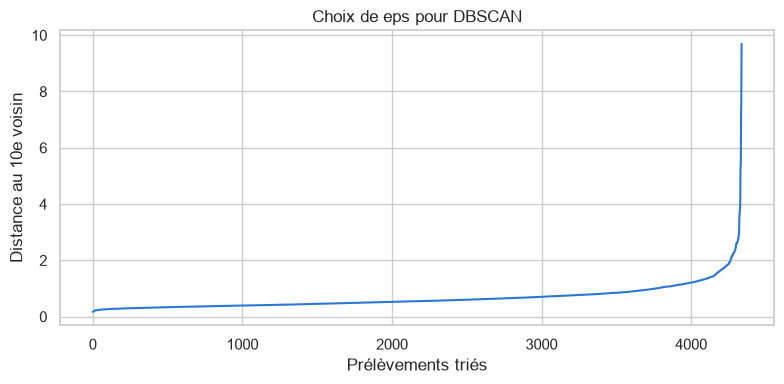

,eps,nb_groupes,nb_points_bruit,% bruit
0,0.800,11,519,11.964
1,1.000,7,273,6.293
2,1.400,2,116,2.674


In [24]:
min_samples = 10
voisins = NearestNeighbors(n_neighbors=min_samples + 1).fit(X)   # +1 car le 1er voisin trouvé est le point lui-même
distances, _ = voisins.kneighbors(X)
distance_10e = np.sort(distances[:, -1])

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(distance_10e, color=COULEURS[0])
ax.set(xlabel="Prélèvements triés", ylabel="Distance au 10e voisin", title="Choix de eps pour DBSCAN")
plt.tight_layout()
plt.show()

# On teste 3 valeurs de eps autour du coude
essais = []
for eps in [0.8, 1.0, 1.4]:
    groupes = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X)
    essais.append({"eps": eps, "nb_groupes": len(set(groupes)) - (1 if -1 in groupes else 0),
                   "nb_points_bruit": (groupes == -1).sum(), "% bruit": (groupes == -1).mean() * 100})
pd.DataFrame(essais)

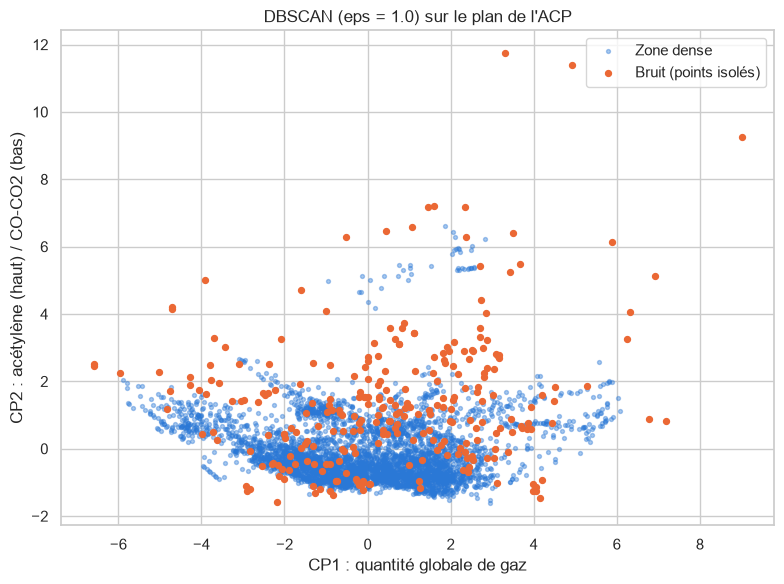

Action recommandée : 21% des points isolés, contre 6% des autres prélèvements

Médiane des gaz (ppm) :
                  H2   CH4  C2H2   C2H4  C2H6      CO       CO2
points isolés 29.000 9.400 0.800 15.000 7.100 302.000 2,220.000
zone dense    16.000 5.300 0.000 22.000 3.000 406.000 3,075.000


In [25]:
eps = 1.0
table["groupe_dbscan"] = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X)
bruit = table["groupe_dbscan"] == -1

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(table.loc[~bruit, "CP1"], table.loc[~bruit, "CP2"], s=8, alpha=0.4, color=COULEURS[0], label="Zone dense")
ax.scatter(table.loc[bruit, "CP1"], table.loc[bruit, "CP2"], s=18, color=COULEURS[1], label="Bruit (points isolés)")
ax.set(xlabel="CP1 : quantité globale de gaz", ylabel="CP2 : acétylène (haut) / CO-CO2 (bas)",
       title=f"DBSCAN (eps = {eps}) sur le plan de l'ACP")
ax.legend()
plt.tight_layout()
plt.show()

# Les points isolés sont-ils plus souvent jugés "à surveiller" par l'expert ?
print(f"Action recommandée : {table.loc[bruit, 'action'].mean():.0%} des points isolés, "
      f"contre {table.loc[~bruit, 'action'].mean():.0%} des autres prélèvements")
print("\nMédiane des gaz (ppm) :")
print(pd.DataFrame({"points isolés": table.loc[bruit, gaz].median(), "zone dense": table.loc[~bruit, gaz].median()}).T.round(1))

**Interprétation :** 
- Le réglage de `eps` change complètement le résultat : avec **0,8**, 11 petits groupes et 12 % de bruit (trop morcelé) ; avec **1,4**, 2 groupes et 3 % de bruit. On retient **eps = 1,0** : 273 points isolés (6,3 %).
- Les **points isolés** sont des prélèvements au **profil inhabituel** : plus d'hydrogène (29 contre 16 ppm), d'éthane (7,1 contre 3,0 ppm) et surtout de l'**acétylène** (médiane 0,8 ppm contre 0). Sur le graphique, ils sont dispersés en bordure du nuage et en haut (axe de l'acétylène).
- L'expert recommande une action pour **21 % d'entre eux**, contre **6 %** pour les autres : **3,5 fois plus**.

→ DBSCAN sert ici de **détecteur d'anomalies** : il isole les prélèvements atypiques, qui sont justement ceux que l'expert juge le plus souvent à surveiller.

## 6. Bilan de l'étape 3
| Méthode | Résultat principal |
|---|---|
| Cible | « action recommandée » reconstruite à partir des tables de l'expert : 260 actions (6,7 %), surtout des demandes de nouveau prélèvement |
| Classification | **Forêt aléatoire** = meilleur modèle : 51 % des actions retrouvées, AUC = 0,82 (KNN : 11 %, arbre : 37 %) |
| Importance des gaz | **H2, CH4, C2H6** pèsent le plus dans la décision ; CO et CO2 le moins |
| K-Means | **2 groupes** (silhouette 0,33) : peu gazés (2 % d'actions) / plus gazés (11,5 % d'actions) |
| CAH | confirme 2 groupes (silhouette 0,33, plus grande marche du dendrogramme) |
| DBSCAN (eps = 1,0) | 273 prélèvements atypiques (6,3 %), riches en acétylène et en hydrogène : 21 % d'actions contre 6 % |

**Limites :**
- La cible est une **décision d'expert**, pas une panne constatée : le modèle reproduit un jugement humain.
- Les modèles n'utilisent que les gaz d'un prélèvement isolé, pas leur **évolution dans le temps**.
- Les groupes se chevauchent (silhouettes autour de 0,33) : ils décrivent des tendances, pas des catégories tranchées.

**Prochaine étape :** visualisation et interprétation (évolution des gaz par transformateur, comparaison avec les seuils IEEE), puis recommandations.